# Mini-modèle ALM fonds euros : V2 stochastique

La V1 projetait le fonds sur un seul chemin de taux. Or le passif réagit de façon asymétrique aux marchés : taux servi jamais négatif, assurés qui rachètent à la valeur comptable quand le marché paie mieux. Le coût de ces asymétries n'apparaît que si l'on fait varier les marchés.

La V2 projette donc le même fonds sur 1 000 scénarios économiques en univers risque neutre. Elle en déduit :
- le **Best Estimate stochastique**, moyenne des flux actualisés ;
- la **TVOG**, écart entre ce BE et celui de l'équivalent certain.

In [1]:
import os, subprocess, sys
if not os.path.exists("src"):
    if os.path.basename(os.getcwd()) == "notebooks":
        os.chdir("..")
    else:
        if not os.path.exists("mini-alm-fonds-euros"):
            subprocess.run(["git", "clone", "https://github.com/TorjmenYou/mini-alm-fonds-euros.git"], check=True)
        os.chdir("mini-alm-fonds-euros")
sys.path.insert(0, os.getcwd())

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.hypotheses import charger_hypotheses
h = charger_hypotheses()

BLEU, ORANGE, VERT, JAUNE = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
ENCRE, ENCRE_2, GRILLE, FOND = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FOND, "axes.facecolor": FOND, "axes.edgecolor": GRILLE,
    "axes.labelcolor": ENCRE_2, "xtick.color": ENCRE_2, "ytick.color": ENCRE_2,
    "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})
pd.set_option("display.precision", 4)

def titre(ax, texte):
    ax.set_title(texte, loc="left", color=ENCRE, fontsize=11)

## 1. Le générateur de scénarios économiques

- **Taux** : modèle de Hull-White à un facteur, calé sur la courbe initiale plate à 3 %. Vitesse de retour à la moyenne a = 5 %, volatilité σ = 1 %.
- **Actions** : rendement log-normal, de tendance le taux court, avec une volatilité de 18 %.
- **Simulation** : exacte au pas annuel, avec 500 paires de tirages antithétiques. Pour chaque trajectoire, on tire ensemble le facteur de taux en fin d'année et son intégrale sur l'année, ce qui donne le déflateur sans erreur de discrétisation.
- **Intervalles de confiance** : calculés sur les moyennes de paires, puisque les deux tirages d'une paire ne sont pas indépendants.

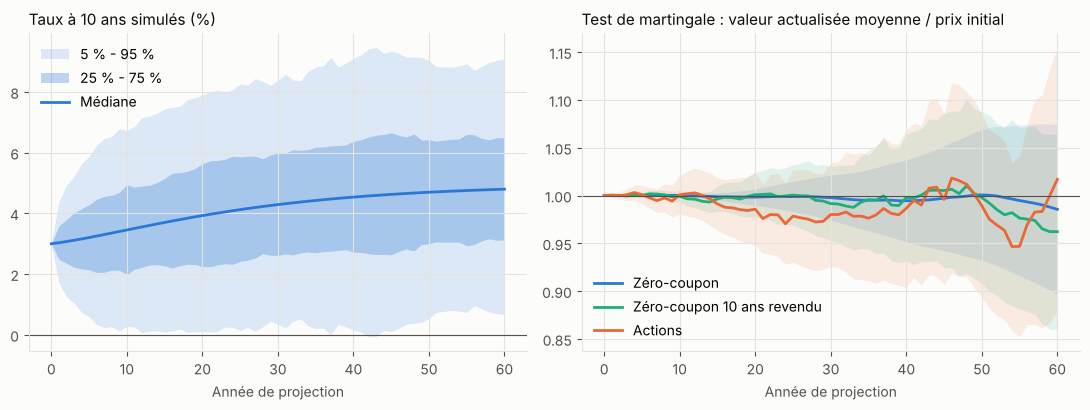

Taux à 10 ans négatif : 4.3 % des scénarios à 30 ans, 2.4 % à 60 ans


In [2]:
from src.gse import GSE
gse = GSE(h)
annees = np.arange(h["horizon_annees"] + 1)
taux10 = np.array([[gse.scenarios()[j].courbe(t).taux_zc(10) for t in annees] for j in range(gse.n)])
q = np.percentile(taux10, [5, 25, 50, 75, 95], axis=0)
m = gse.test_martingale()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axes[0]
ax.fill_between(annees, q[0] * 100, q[4] * 100, color=BLEU, alpha=0.15, linewidth=0, label="5 % - 95 %")
ax.fill_between(annees, q[1] * 100, q[3] * 100, color=BLEU, alpha=0.30, linewidth=0, label="25 % - 75 %")
ax.plot(annees, q[2] * 100, color=BLEU, linewidth=2, label="Médiane")
ax.axhline(0, color=ENCRE_2, linewidth=0.8)
titre(ax, "Taux à 10 ans simulés (%)")
ax.set_xlabel("Année de projection")
ax.legend(frameon=False, loc="upper left")

ax = axes[1]
for cle, couleur, nom in [("zero_coupon", BLEU, "Zéro-coupon"), ("obligation", VERT, "Zéro-coupon 10 ans revendu"),
                          ("actions", ORANGE, "Actions")]:
    ax.fill_between(annees, m[cle] - m["ic_" + cle], m[cle] + m["ic_" + cle], color=couleur, alpha=0.12, linewidth=0)
    ax.plot(annees, m[cle], color=couleur, linewidth=2, label=nom)
ax.axhline(1, color=ENCRE_2, linewidth=0.8)
titre(ax, "Test de martingale : valeur actualisée moyenne / prix initial")
ax.set_xlabel("Année de projection")
ax.legend(frameon=False, loc="lower left")
fig.tight_layout()
fig.savefig("figures/gse.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Taux à 10 ans négatif : {100 * (taux10[:, 30] < 0).mean():.1f} % des scénarios à 30 ans, "
      f"{100 * (taux10[:, -1] < 0).mean():.1f} % à 60 ans")

Lecture :
- **Taux** : la dispersion s'élargit avec l'horizon. Le modèle de Hull-White est gaussien, donc le taux peut devenir négatif. La médiane monte de 3 % à près de 5 % à 60 ans : en univers risque neutre, l'espérance des taux futurs dépasse les taux forward initiaux (correction de convexité du modèle de Hull-White).
- **Test de martingale** : actualisés au déflateur, trois actifs valent en moyenne leur prix initial, dans leur intervalle de confiance à 95 % (zones colorées). Ces trois actifs sont un zéro-coupon, un zéro-coupon de 10 ans revendu au prix du modèle, et l'indice actions. Le GSE est donc bien risque neutre, et la formule de prix des obligations est cohérente avec lui. C'est la condition pour que le BE soit une valeur de marché.

## 2. Best Estimate et TVOG

In [3]:
from src.stochastique import projeter_stochastique, tvog
res = projeter_stochastique(h, gse)
t = tvog(h, res)
s = res["synthese"]
pd.Series({
    "Valeur de marché de l'actif": s["vm_actif_initial"],
    "BE équivalent certain (V1, scénario central)": t["be_equivalent_certain"],
    "BE stochastique": s["be"],
    "BE : demi-largeur de l'intervalle à 95 %": s["ic_be"],
    "TVOG": t["tvog"],
    "TVOG en % du BE stochastique": 100 * t["tvog"] / s["be"],
    "Valeur pour l'assureur (actif - BE)": s["valeur_assureur"],
    "Fuite moyenne": s["fuite"],
    "Fuite : demi-largeur de l'intervalle à 95 %": s["ic_fuite"],
}).round(2).to_frame("Montant")

,Montant
Valeur de marché de l'actif,1078.20
"BE équivalent certain (V1, scénario central)",966.73
BE stochastique,987.35
BE : demi-largeur de l'intervalle à 95 %,6.23
TVOG,20.62
TVOG en % du BE stochastique,2.09
Valeur pour l'assureur (actif - BE),90.85
Fuite moyenne,1.32
Fuite : demi-largeur de l'intervalle à 95 %,2.84


Lecture :
- **TVOG** : le BE stochastique dépasse l'équivalent certain d'environ 21, soit environ 2 % du BE. L'intervalle à 95 % est d'environ ±6.
- **Valeur pour l'assureur** : elle passe d'environ 111 en V1 à environ 91. L'écart, c'est la TVOG.
- **Fuite moyenne** : elle reste dans son intervalle de confiance. Aucune valeur n'est créée ni perdue par le modèle, à l'erreur de Monte-Carlo près.

### D'où vient la TVOG ?

On fait tourner les 8 combinaisons de trois mécanismes, sur les mêmes tirages : le plancher de taux servi au TMG, les rachats dynamiques et le lissage par la PPB. Chaque mécanisme reçoit sa valeur de Shapley, c'est-à-dire sa contribution moyenne sur tous les ordres d'activation possibles : les effets d'interaction sont ainsi répartis à parts égales, au lieu d'être attribués au dernier mécanisme ajouté.

In [4]:
from src.stochastique import decomposer_tvog
combinaisons, shapley = decomposer_tvog(h)
combinaisons = combinaisons.rename(columns={"be_equivalent_certain": "BE équivalent certain", "be_stochastique": "BE stochastique",
                                            "tvog": "TVOG", "ic_tvog": "IC 95 % (±)"})
combinaisons.replace({True: "oui", False: "non"}).round(1)

,Plancher de taux servi (TMG),Rachats dynamiques,Lissage par la PPB,BE équivalent certain,BE stochastique,TVOG,IC 95 % (±)
0,non,non,non,966.7,959.3,-7.4,2.6
1,oui,non,non,966.7,962.9,-3.8,3.3
2,non,oui,non,966.7,989.2,22.4,5.0
3,non,non,oui,966.7,955.6,-11.1,2.7
4,oui,oui,non,966.7,993.7,27.0,6.9
5,oui,non,oui,966.7,957.5,-9.2,3.2
6,non,oui,oui,966.7,984.9,18.1,4.9
7,oui,oui,oui,966.7,987.4,20.6,6.2


In [5]:
shapley.round(1).to_frame("Contribution à la TVOG")

,Contribution à la TVOG
Plancher de taux servi (TMG),3.1
Rachats dynamiques,29.9
Lissage par la PPB,-5.0
Sans aucun des trois mécanismes,-7.4
TVOG du modèle complet,20.6


Lecture (la TVOG est connue à environ ±6 près avec 1 000 scénarios ; les écarts entre combinaisons, calculés sur les mêmes tirages, sont plus précis) :
- **Sans aucun des trois mécanismes**, la TVOG est déjà négative, d'environ -7 (±2,6). Explication plausible, non isolée par un test dédié : en univers risque neutre, les taux montent en moyenne et le taux servi suit avec retard, car le portefeuille ne se renouvelle que par dixièmes. Les assurés reçoivent donc moins que dans l'équivalent certain, où les taux restent à 3 %.
- **Les rachats dynamiques** apportent environ +30 : c'est l'essentiel de la TVOG. Racheter, c'est exercer une option de vente à la valeur comptable, au moment où les taux montent et où l'épargne vaut moins que sa valeur comptable.
- **Le plancher de taux servi au TMG** apporte environ +3 : les scénarios où il joue, ceux de taux durablement négatifs, sont rares.
- **Le lissage par la PPB** retire environ 5. Interprétation plausible : la PPB met en réserve les excédents des bons scénarios et soutient le taux servi quand le marché monte, ce qui limite les rachats coûteux.
- **Au total**, -7 + 30 + 3 - 5 donne bien la TVOG du modèle complet, environ 21.

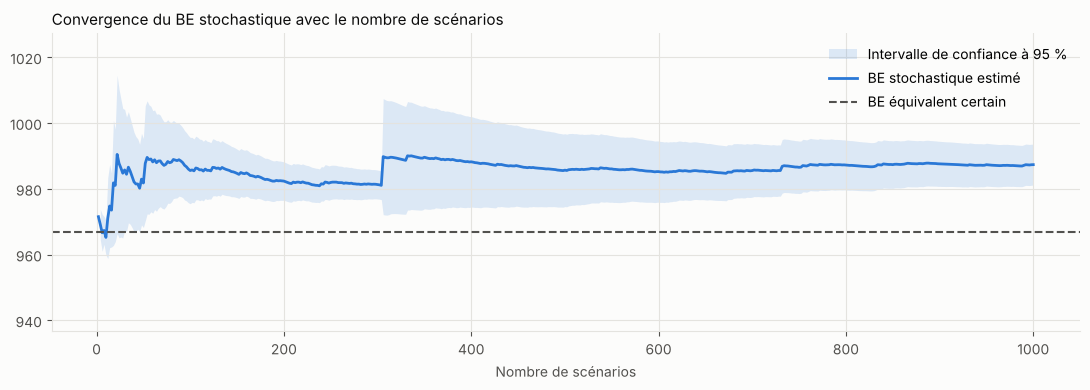

In [6]:
be = res["par_scenario"]["be"].to_numpy()
moitie = len(be) // 2
paires = (be[:moitie] + be[moitie:]) / 2
k = np.arange(1, moitie + 1)
moyenne = np.cumsum(paires) / k
ecart = np.array([paires[:i].std(ddof=1) if i > 1 else np.nan for i in k])
demi = 1.96 * ecart / np.sqrt(k)

fig, ax = plt.subplots(figsize=(11, 4))
ax.fill_between(2 * k, moyenne - demi, moyenne + demi, color=BLEU, alpha=0.15, linewidth=0, label="Intervalle de confiance à 95 %")
ax.plot(2 * k, moyenne, color=BLEU, linewidth=2, label="BE stochastique estimé")
ax.axhline(t["be_equivalent_certain"], color=ENCRE_2, linewidth=1.5, linestyle="--", label="BE équivalent certain")
ax.set_ylim(t["be_equivalent_certain"] - 30, s["be"] + 40)
titre(ax, "Convergence du BE stochastique avec le nombre de scénarios")
ax.set_xlabel("Nombre de scénarios")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
fig.savefig("figures/convergence_be.png", dpi=150, bbox_inches="tight")
plt.show()

Lecture :
- **Seule la moyenne a un sens économique.** Le BE d'un scénario isolé dépend surtout de son déflateur : des taux bas donnent une actualisation faible et un BE élevé.
- **Convergence** : à 1 000 scénarios, l'estimation est connue à environ ±6. L'étude ci-dessous chiffre la précision obtenue avec plus de scénarios.
- **Les sauts**, comme celui vers 300 scénarios, viennent de quelques scénarios extrêmes où les taux restent durablement négatifs.

### Convergence Monte-Carlo

Le script `scripts/convergence.py` relance le calcul avec 1 000, 2 000, 5 000 et 10 000 scénarios (graine fixe), et écrit `resultats/convergence.csv`. On en lit les résultats ici, sans les recalculer.

In [7]:
conv = pd.read_csv("resultats/convergence.csv").set_index("scenarios")
conv = conv[["be", "ecart_type_estimateur_be", "ic95_be", "tvog", "fdb", "ic95_fdb", "fuite", "ic95_fuite", "part_scenarios_avec_apport", "duree_s"]]
conv.columns = ["BE", "Écart-type de l'estimateur", "IC 95 % (±)", "TVOG", "FDB", "IC 95 % FDB (±)", "Fuite", "IC 95 % fuite (±)",
                "Part des scénarios avec apport", "Durée (s)"]
conv.round(2)

,BE,Écart-type de l'estimateur,IC 95 % (±),TVOG,FDB,IC 95 % FDB (±),Fuite,IC 95 % fuite (±),Part des scénarios avec apport,Durée (s)
scenarios,,,,,,,,,,
1000,987.35,3.18,6.23,20.62,178.60,2.02,1.32,2.84,0.01,16.97
2000,987.17,1.88,3.69,20.44,178.34,1.44,0.70,2.01,0.01,31.20
5000,988.37,1.25,2.45,21.64,178.27,0.94,-0.22,1.39,0.02,80.48
10000,988.19,0.84,1.64,21.45,179.08,0.67,-0.32,0.96,0.02,160.50


Lecture :
- **Précision** : l'écart-type de l'estimateur du BE baisse à peu près comme 1/√n, de 3,2 à 0,8 quand on passe de 1 000 à 10 000 scénarios. Les estimations restent dans les intervalles de confiance les unes des autres, entre 987 et 988.
- **Ce qu'on peut affirmer avec 1 000 scénarios** : le BE à environ ±6 près (0,6 %), mais la TVOG seulement à ±6 près, soit environ 30 % de sa valeur. Pour publier une TVOG précise, il faut 10 000 scénarios (TVOG d'environ 21,5, ±1,6).
- **La fuite** reste dans son intervalle de confiance à toutes les tailles.
- **Le temps de calcul** croît linéairement avec le nombre de scénarios : de 15 à 20 secondes par tranche de 1 000 scénarios selon la machine (colonne « Durée (s) »).
- **Un à deux pour cent des scénarios** demandent un apport de capital de l'assureur. Ce sont des scénarios de taux durablement négatifs, où l'actif ne suffit plus à payer le taux garanti.

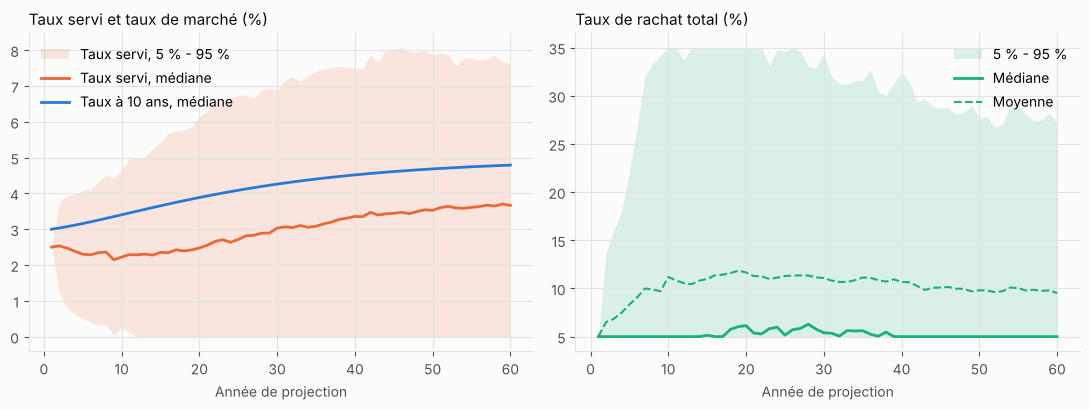

In [8]:
traj = res["trajectoires"]
def bande(col):
    g = traj[col].groupby(level="annee")
    return g.quantile(0.05), g.median(), g.quantile(0.95)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True)
ax = axes[0]
b5, med, b95 = bande("taux_servi")
ax.fill_between(med.index[1:], b5[1:] * 100, b95[1:] * 100, color=ORANGE, alpha=0.15, linewidth=0, label="Taux servi, 5 % - 95 %")
ax.plot(med.index[1:], med[1:] * 100, color=ORANGE, linewidth=2, label="Taux servi, médiane")
_, med10, _ = bande("taux_10ans")
ax.plot(med10.index[1:], med10[1:] * 100, color=BLEU, linewidth=2, label="Taux à 10 ans, médiane")
titre(ax, "Taux servi et taux de marché (%)")
ax.set_xlabel("Année de projection")
ax.legend(frameon=False, loc="upper left")

ax = axes[1]
b5, med, b95 = bande("taux_rachat")
ax.fill_between(med.index[1:], b5[1:] * 100, b95[1:] * 100, color=VERT, alpha=0.15, linewidth=0, label="5 % - 95 %")
ax.plot(med.index[1:], med[1:] * 100, color=VERT, linewidth=2, label="Médiane")
ax.plot(res["moyennes"].index[1:], res["moyennes"]["taux_rachat"][1:] * 100, color=VERT, linewidth=1.5, linestyle="--", label="Moyenne")
titre(ax, "Taux de rachat total (%)")
ax.set_xlabel("Année de projection")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
fig.savefig("figures/trajectoires_stochastiques.png", dpi=150, bbox_inches="tight")
plt.show()

Lecture :
- **Taux servi** : il reste sous le taux de marché. Le portefeuille obligataire ne se renouvelle que par dixièmes, et l'assureur prélève ses chargements et sa marge. Cet écart nourrit les rachats conjoncturels.
- **Rachats** : la médiane reste proche du rachat structurel de 5 %. La moyenne et le haut de la bande montent nettement, tirés par les scénarios de hausse rapide des taux. C'est la source principale de la TVOG.

## 3. Limites de la V2
- Un seul facteur de taux et une volatilité constante. Le GSE n'est pas calibré sur des prix d'options (swaptions), comme le serait un GSE de production.
- Taux négatifs non bornés : c'est un choix du modèle gaussien.
- Actions et taux indépendants.
- 1 000 scénarios par défaut : la précision suffit pour le BE, pas pour une TVOG publiée (voir l'étude de convergence).